In [10]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict
from dotenv import load_dotenv

In [4]:
load_dotenv()

True

In [5]:
model = ChatGroq(model="openai/gpt-oss-20b")

In [6]:
# Create a state

class LLMState(TypedDict):
    question : str
    answer   : str

In [9]:
def llm_qa(state : LLMState) -> LLMState:
    # extract the question from answer
    question = state['question']

    # from the prompt
    prompt = f'Answer the following question :{question}'

    # ask the question to llm
    answer = model.invoke(prompt).content

    # update the answer in the state
    state['answer'] = answer

    return state

In [12]:
# Create our graph

graph = StateGraph(LLMState)

# add node
graph.add_node('llm_qa', llm_qa)

# add edges
graph.add_edge(START, 'llm_qa')
graph.add_edge('llm_qa', END)

# Compile the graph
workflow = graph.compile()



In [13]:
# Execute

initial_state = {'question':'How far is moon from the earth ?'}

final_state = workflow.invoke(initial_state)

print(final_state['answer'])


The Moon orbits Earth at an average distance of about **384 400 km** (≈ 238 900 miles). Because the orbit is elliptical, the distance varies:

| Position | Distance |
|----------|----------|
| Perigee (closest) | ≈ 363 300 km (≈ 225 600 mi) |
| Apogee (farthest) | ≈ 405 500 km (≈ 251 900 mi) |

So, on average, the Moon is roughly 384 000 km from Earth.


### Prompt chaining_workflow

##### to generate blog

In [19]:
class BlogState(TypedDict):
    title : str
    outline : str
    content : str


In [20]:
def create_outline(state: BlogState) -> BlogState:

    # fetch title
    title = state['title']

    # call ll to generate outline
    prompt = f'Generate an outline for a blog on the topic -{title}'
    outline = model.invoke(prompt).content
    
    # update state
    state['outline'] = outline

    return state


In [21]:
def create_blog(state : BlogState) -> BlogState:
    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the following outline \n{outline}'

    content = model.invoke(prompt)

    state['content'] = content

    return state


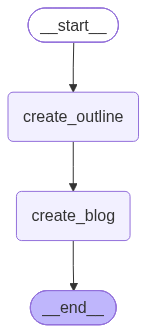

In [29]:
graph = StateGraph(BlogState)

# Nodes
graph.add_node('create_outline',create_outline)
graph.add_node('create_blog',create_blog)

#Edge
graph.add_edge(START,'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', END)

# Compile
graph.compile()

In [23]:
# Execute
initial_state = {'title':'rise of AI in India'}

final_state = workflow.invoke(initial_state)

print(final_state['content'])

content='# The Rise of AI in India: From Research Labs to Global Powerhouses  \n\n---\n\n## 1. Introduction  \n\n> **Did you know?**  \n> • India’s AI market is projected to hit **$10\u202fbillion** by 2026, up from **$1.4\u202fbillion** in 2020.  \n> • Over **1,500** AI‑focused startups have emerged in the last decade, raising **$3\u202fbillion** in VC capital.  \n> • AI has already created **≈\u202f150,000** new jobs across data science, ML engineering, and AI product management.  \n\nIndia’s AI trajectory is no longer a footnote; it is rewriting the country’s economic playbook, reshaping society, and positioning the nation as a global technology contender. In this post we’ll trace the journey from nascent research labs to a vibrant ecosystem, highlight real‑world use‑cases, unpack policy initiatives, and look ahead to what the next decade holds.\n\n---\n\n## 2. A Brief History of AI in India  \n\n| Era | Milestone | Significance |\n|-----|-----------|--------------|\n| **1980s‑90s**

In [24]:
print(final_state['outline'])

# Blog Outline  
**Title:** *The Rise of AI in India: From Research Labs to Global Powerhouses*

---

## 1. Introduction  
- Hook: Quick stats (e.g., AI market size, job creation, startup count).  
- Thesis: India’s AI trajectory is reshaping its economy, society, and global standing.  
- Preview of key themes: history, ecosystem, industry impact, challenges, future.

---

## 2. A Brief History of AI in India  
| Era | Milestone | Significance |
|-----|-----------|--------------|
| 1980s‑90s | Early research at IITs, CSIR, and IIT Bombay | Foundations in machine learning & computational linguistics |
| 2000s | National AI strategy drafts, AI research grants | Formal recognition of AI’s strategic importance |
| 2010s | Rise of AI startups, AI labs in corporates | Transition from academia to industry |
| 2020‑present | AI in 4IR, large‑scale government AI pilots | AI as a national priority and export commodity |

- Highlight key personalities (e.g., Dr. Ajay Narayanan, Dr. Anurag Kumar).

In [28]:
print(final_state['content'].content)

# The Rise of AI in India: From Research Labs to Global Powerhouses  

---

## 1. Introduction  

> **Did you know?**  
> • India’s AI market is projected to hit **$10 billion** by 2026, up from **$1.4 billion** in 2020.  
> • Over **1,500** AI‑focused startups have emerged in the last decade, raising **$3 billion** in VC capital.  
> • AI has already created **≈ 150,000** new jobs across data science, ML engineering, and AI product management.  

India’s AI trajectory is no longer a footnote; it is rewriting the country’s economic playbook, reshaping society, and positioning the nation as a global technology contender. In this post we’ll trace the journey from nascent research labs to a vibrant ecosystem, highlight real‑world use‑cases, unpack policy initiatives, and look ahead to what the next decade holds.

---

## 2. A Brief History of AI in India  

| Era | Milestone | Significance |
|-----|-----------|--------------|
| **1980s‑90s** | Early research at IITs, CSIR, IIT Bombay | La